# خوشه‌بندی تصاویر حیات‌وحش با HDBSCAN و Embeddingهای DINOv2

<div dir="rtl" style="text-align: right;">

## هدف

هدف این تحلیل، کشف گروه‌های طبیعی در تصاویر بر اساس شباهت بصری است؛ بدون استفاده از برچسب گونه یا رده در مرحله خوشه‌بندی. اطلاعات زیستی، مکانی و کیفیت مشاهده فقط پس از خوشه‌بندی برای تفسیر و ارزیابی خارجی استفاده می‌شوند.

داده شامل **۲۸٬۱۳۲ تصویر** و embeddingهای **۳۸۴بعدی DINOv2** است. چون بردارها قبلاً L2-normalize شده‌اند، فاصله اقلیدسی روی بردارهای واحد با فاصله کسینوسی رابطه یکنواخت دارد:

$$
\|x-y\|_2^2 = \|x\|_2^2+\|y\|_2^2-2x^\top y
=2\left(1-\cos(x,y)\right)
$$

بنابراین، برای بردارهای واحد، استفاده از Euclidean در HDBSCAN انتخاب عملی مناسبی است و از پیاده‌سازی‌های عمومی/کندتر فاصله cosine پرهیز می‌کند.

---

## HDBSCAN چگونه کار می‌کند؟

HDBSCAN مخفف **Hierarchical Density-Based Spatial Clustering of Applications with Noise** است. برخلاف K-Means تعداد خوشه‌ها را از قبل نمی‌خواهد و می‌تواند نقاط کم‌تراکم را Noise تشخیص دهد.

### ۱. فاصله هسته‌ای (Core Distance)

برای هر نقطه $x_i$، فاصله تا $k$-اُمین همسایه نزدیک تعریف می‌شود:

$$
d_{\mathrm{core},k}(x_i)=d\!\left(x_i,x_{i}^{(k)}\right)
$$

که $k$ معمولاً با پارامتر `min_samples` کنترل می‌شود. مقدار بزرگ‌تر، تعریف سخت‌گیرانه‌تری از چگالی ایجاد می‌کند.

### ۲. فاصله دست‌یافتنی متقارن (Mutual Reachability)

فاصله خام با فاصله هسته‌ای دو نقطه تعدیل می‌شود:

$$
d_{\mathrm{mr}}(a,b)=
\max\left\{d_{\mathrm{core}}(a),\;d_{\mathrm{core}}(b),\;d(a,b)\right\}
$$

این تبدیل اثر نواحی کم‌تراکم را کاهش می‌دهد و ساختار چگالی را بهتر نمایان می‌کند.

### ۳. درخت پوشای کمینه و سلسله‌مراتب

HDBSCAN بر اساس فاصله‌های mutual-reachability یک **Minimum Spanning Tree** می‌سازد و با حذف تدریجی یال‌های بلند، سلسله‌مراتب خوشه‌ها را به دست می‌آورد.

پارامتر چگالی معمولاً به صورت زیر بیان می‌شود:

$$
\lambda = \frac{1}{d_{\mathrm{mr}}}
$$

خوشه‌ها در سطوح مختلف چگالی ظاهر می‌شوند و سپس الگوریتم پایدارترین شاخه‌ها را انتخاب می‌کند.

### ۴. پایداری خوشه (Cluster Stability)

به‌صورت شهودی، خوشه‌ای مطلوب است که در بازه بزرگی از چگالی باقی بماند. پایداری شاخه $C$ را می‌توان به شکل زیر نوشت:

$$
S(C)=\sum_{x\in C}
\left(\lambda_{\mathrm{leave}}(x,C)-\lambda_{\mathrm{birth}}(C)\right)
$$

HDBSCAN با روش انتخاب خوشه (معمولاً `eom`) خوشه‌های پایدارتر را برمی‌گزیند. نقاطی که در خوشه منتخب قرار نمی‌گیرند، برچسب **-1** یا **Noise** می‌گیرند.

---

## چه کار می‌کنیم؟

1. embeddingها را از `data/embeddings/images_dinov2.parquet` می‌خوانیم.
2. اطلاعات تصویر و مشاهده را با `image_id` و `observation_uuid` متصل می‌کنیم.
3. بردارها را از نظر ابعاد، مقادیر گمشده و نرمال‌بودن بررسی می‌کنیم.
4. دو فضای آزمایشی داریم:
   - **original**: فضای اصلی ۳۸۴بعدی؛ مرجع وفادارتر، اما ممکن است کندتر باشد.
   - **umap**: کاهش غیرخطی به ۱۰ تا ۲۰ بعد با UMAP و سپس HDBSCAN؛ گزینه عملی‌تر برای کشف ساختار محلی.
5. برای نمایش، یک UMAP مستقل دوبعدی می‌سازیم. این نمایش صرفاً بصری است و مبنای انتخاب خوشه‌ها نیست.
6. پارامترهای `min_cluster_size` و `min_samples` را آزمایش می‌کنیم.
7. معیارها، اندازه خوشه‌ها، نسبت Noise و پروفایل زیستی خوشه‌ها را گزارش می‌کنیم.
8. نمونه‌های نماینده و Noise را برای بازبینی انسانی ذخیره می‌کنیم.

---

## پارامترهای اصلی

- **`min_cluster_size`**: کوچک‌ترین اندازه خوشه قابل قبول. مقدار بزرگ‌تر خوشه‌های کوچک را حذف/ادغام می‌کند.
- **`min_samples`**: میزان محافظه‌کاری در تعریف ناحیه پرتراکم. مقدار بزرگ‌تر معمولاً Noise بیشتری ایجاد می‌کند.
- **`cluster_selection_method`**: `eom` خوشه‌های پایدارتر و معمولاً درشت‌تر را انتخاب می‌کند؛ `leaf` خوشه‌های ریزتری می‌دهد.
- **`cluster_selection_epsilon`**: آستانه اختیاری برای جلوگیری از شکستن بیش از حد خوشه‌ها؛ در اجرای پایه صفر می‌ماند.

**مقادیر شروع پیشنهادی، نه جواب قطعی:**

$$
\texttt{min\_cluster\_size} \in \{30,\;50,\;100\}
\qquad
\texttt{min\_samples} \in \{5,\;10,\;20\}
$$

---

## ارزیابی و تفسیر

- **DBCV**: معیار داخلی متناسب با خوشه‌بندی چگالی‌محور؛ مقدار بالاتر بهتر است.
- **Silhouette**: روی نمونه ثابت و فقط نقاط خوشه‌بندی‌شده محاسبه می‌شود؛ مقدار بالاتر بهتر است. برای HDBSCAN معیار قطعی انتخاب نیست.
- **Noise ratio**: سهم نقاط با برچسب **-1**.
- **Cluster size distribution**: اندازه و عدم‌توازن خوشه‌ها.
- **ARI / AMI بین اجراها**: برای سنجش پایداری نسبت به تغییر پارامتر یا زیرنمونه‌گیری؛ Noise باید جداگانه نیز گزارش شود.
- **Taxonomic purity / entropy / NMI**: فقط بعد از خوشه‌بندی و برای تفسیر ارتباط خوشه‌ها با رده‌ها و گونه‌ها.

---

## نکات روش‌شناختی مهم

1. `species_id`، `taxon_class_name`، `taxon_family_name` و مختصات جغرافیایی وارد ورودی HDBSCAN نمی‌شوند؛ در غیر این صورت دیگر خوشه‌بندی صرفاً بصری نیست.
2. اگر چند تصویر از یک مشاهده وجود داشته باشد، برای ارزیابی Train/Test یا زیرنمونه‌گیری باید `observation_uuid` را گروه‌بندی کرد تا تصاویر یک مشاهده بین بخش‌ها نشت نکنند.
3. UMAP می‌تواند هندسه و چگالی را تغییر دهد. بنابراین نتیجه HDBSCAN روی UMAP باید با اجرای مرجع روی فضای اصلی (در صورت امکان محاسباتی) مقایسه شود.
4. نمودار دوبعدی UMAP برای فهم بصری است؛ فاصله‌های دوبعدی را نباید معادل فاصله واقعی در embedding اصلی تفسیر کرد.
5. Noise الزاماً تصویر بد نیست؛ ممکن است گونه کمیاب، زاویه خاص، مرحله زندگی متفاوت یا تصویر واقعاً نامعمول باشد. بازبینی انسانی ضروری است.

</div>


In [15]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA
from pathlib import Path
import json, itertools, warnings
import hdbscan

X = np.vstack(df["embedding"].apply(lambda v: np.asarray(v, dtype=np.float32)).to_numpy())
X = normalize(X)
ROOT = Path.cwd().parent
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
EMBED_PATH = ROOT / "data/embeddings/images_dinov2.parquet"
df = pd.read_parquet(EMBED_PATH)
df.head(), df.shape, df.dtypes


(                               image_id                      observation_uuid  \
 0  001cc818-ac3e-4750-979d-4d2d9d8358f7  001cc818-ac3e-4750-979d-4d2d9d8358f7   
 1  0096e64b-71cf-42d9-b8ad-519bcacd14a8  0096e64b-71cf-42d9-b8ad-519bcacd14a8   
 2  01057a20-6a12-4d43-8a0d-edaead5284e5  01057a20-6a12-4d43-8a0d-edaead5284e5   
 3  014f362c-2e4e-4e51-aa4e-76b6d2315a32  014f362c-2e4e-4e51-aa4e-76b6d2315a32   
 4  0162c51c-4627-417c-b6f2-b75f3164ba69  0162c51c-4627-417c-b6f2-b75f3164ba69   
 
                                           image_path animal_present  \
 0  d:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2...           None   
 1  d:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2...           None   
 2  d:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2...           None   
 3  d:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2...           None   
 4  d:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2...           None   
 
                                            embedding  
 0  [-0.04448, -

چون نرمال شده فاصله اقلیدسی با کسینوس رابطه یکنواخت داره .

In [3]:
EMBED_COL = "embedding"
ID_COL = "image_id"
X = np.vstack(df[EMBED_COL].apply(lambda v: np.asarray(v, dtype=np.float32)).to_numpy())
print("Shape:", X.shape)
print("Finite:", np.isfinite(X).all())
print("Norm min/median/max:", np.linalg.norm(X, axis=1).min(),
      np.median(np.linalg.norm(X, axis=1)),
      np.linalg.norm(X, axis=1).max())


Shape: (28132, 384)
Finite: True
Norm min/median/max: 0.9999998 1.0 1.0000001


In [4]:
embedding_norm = np.linalg.norm(X, axis=1)
embedding_mean = X.mean(axis=1)
embedding_std = X.std(axis=1)
feature_table = df[[ID_COL]].copy()
feature_table["embedding_norm"] = embedding_norm
feature_table["embedding_mean"] = embedding_mean
feature_table["embedding_std"] = embedding_std
feature_table.describe(include="all")


,image_id,embedding_norm,embedding_mean,embedding_std
count,28132,2.813200e+04,28132.000000,28132.000000
unique,28132,NaN,NaN,NaN
top,001cc818-ac3e-4750-979d-4d2d9d8358f7,NaN,NaN,NaN
freq,1,NaN,NaN,NaN
mean,NaN,1.000000e+00,-0.000083,0.051027
std,NaN,3.849995e-08,0.000599,0.000005
min,NaN,9.999998e-01,-0.002547,0.050967
25%,NaN,9.999999e-01,-0.000484,0.051026
50%,NaN,1.000000e+00,-0.000072,0.051029
75%,NaN,1.000000e+00,0.000327,0.051031


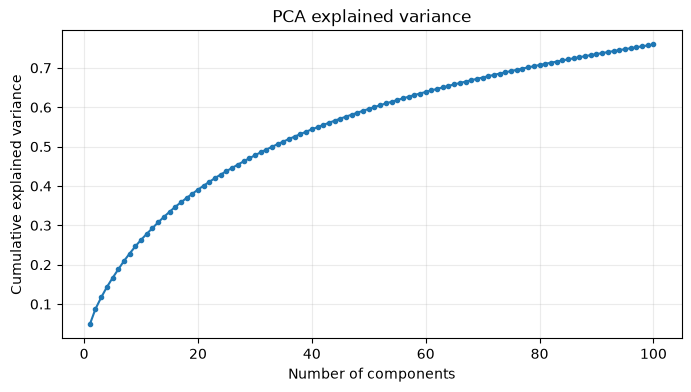

In [6]:
assert X.ndim == 2
assert np.isfinite(X).all()
norms = np.linalg.norm(X, axis=1)
X_norm = normalize(X)
pca = PCA(n_components=min(100, X.shape[1]), random_state=42)
Xp = pca.fit_transform(X_norm)
cumvar = np.cumsum(pca.explained_variance_ratio_)
plt.figure(figsize=(8,4))
plt.plot(np.arange(1, len(cumvar)+1), cumvar, marker=".")
plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance")
plt.title("PCA explained variance"); plt.grid(alpha=.25)
plt.show()

In [7]:
images = pd.read_parquet(ROOT / "data/processed/images.parquet")
observations = pd.read_parquet(ROOT / "data/processed/observations.parquet")
species = pd.read_parquet(ROOT / "data/processed/species.parquet")
print(images.shape, observations.shape, species.shape)
print("Image IDs unique:", images.image_id.is_unique)
print("Observation UUID unique:", observations.uuid.is_unique)


(28132, 4) (28132, 18) (1107, 5)
Image IDs unique: True
Observation UUID unique: True


In [8]:
# ذخیره جدول تشخیصی در صورت نیاز
out = ROOT / "reports/tables"
out.mkdir(parents=True, exist_ok=True)
feature_table.to_parquet(out / "embedding_basic_features.parquet", index=False)
print("Saved", out / "embedding_basic_features.parquet")


Saved d:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2\reports\tables\embedding_basic_features.parquet


In [9]:
spaces = {"original_384d": X}
for n in [50, 75]:
    n = min(n, X.shape[1])
    spaces[f"pca_{n}d"] = PCA(n_components=n, random_state=42).fit_transform(X)
[(name, z.shape) for name, z in spaces.items()]


[('original_384d', (28132, 384)),
 ('pca_50d', (28132, 50)),
 ('pca_75d', (28132, 75))]

In [16]:
param_grid = list(itertools.product([30, 50], [5, 10], ["eom"]))
rows, fitted = [], {}
for space_name, Z in spaces.items():
    for mcs, ms, selection in param_grid:
        clusterer = hdbscan.HDBSCAN(
            min_cluster_size=mcs, min_samples=ms,
            metric="euclidean", cluster_selection_method=selection,
            prediction_data=True, gen_min_span_tree=True
        )
        labels = clusterer.fit_predict(Z)
        ncl = len(set(labels) - {-1})
        nonnoise = labels != -1
        sil = np.nan
        if ncl >= 2 and nonnoise.sum() > ncl:
            ids = np.flatnonzero(nonnoise)
            if len(ids) > 6000:
                ids = np.random.default_rng(42).choice(ids, 6000, replace=False)
            try: sil = silhouette_score(Z[ids], labels[ids])
            except Exception: pass
        try: dbcv = float(clusterer.relative_validity_)
        except Exception: dbcv = np.nan
        key = (space_name, mcs, ms, selection)
        fitted[
            key] = (clusterer, labels)
        rows.append({"space":space_name, "min_cluster_size":mcs,
                     "min_samples":ms, "selection":selection,
                     "n_clusters":ncl, "noise_ratio":float((~nonnoise).mean()),
                     "silhouette_non_noise":sil, "relative_validity_dbcv":dbcv})
results = pd.DataFrame(rows).sort_values(["relative_validity_dbcv","silhouette_non_noise"], ascending=False)
results


,space,min_cluster_size,min_samples,selection,n_clusters,noise_ratio,silhouette_non_noise,relative_validity_dbcv
3,original_384d,50,10,eom,27,0.728245,NaN,0.102746
11,pca_75d,50,10,eom,39,0.747512,NaN,0.067397
0,original_384d,30,5,eom,48,0.725615,NaN,0.048515
2,original_384d,50,5,eom,36,0.729738,NaN,0.048045
6,pca_50d,50,5,eom,25,0.566081,NaN,0.037237
7,pca_50d,50,10,eom,23,0.569885,NaN,0.030952
4,pca_50d,30,5,eom,3,0.181004,NaN,0.000047
8,pca_75d,30,5,eom,2,0.120894,NaN,0.000033
5,pca_50d,30,10,eom,2,0.170233,NaN,0.000023
10,pca_75d,50,5,eom,2,0.218257,NaN,0.000022


چرا هیچ کس به من نگفت اگه از کاهش بعد استفاده نکنی و با همون  امبدینگ اصلی خوشه بندی کنی تا بی نهایت و بعد از اون طول میکشه؟

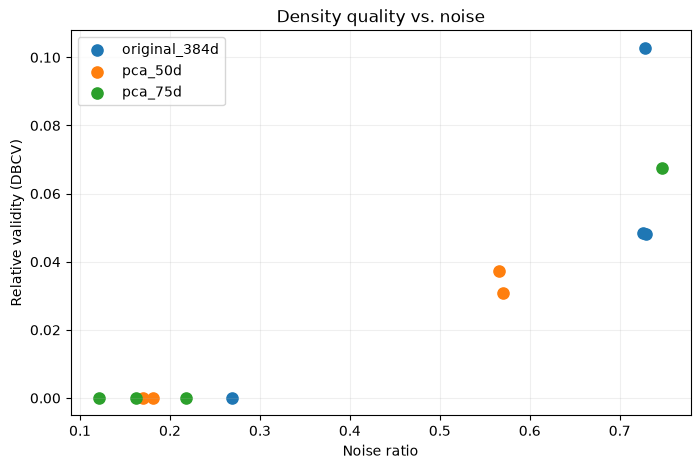

In [17]:
fig, ax = plt.subplots(figsize=(8,5))
for space_name, g in results.groupby("space"):
    ax.scatter(g["noise_ratio"], g["relative_validity_dbcv"], label=space_name, s=65)
ax.set_xlabel("Noise ratio"); ax.set_ylabel("Relative validity (DBCV)")
ax.set_title("Density quality vs. noise"); ax.legend(); ax.grid(alpha=.2)
plt.show()


In [18]:
SELECTED_KEY = ("pca_50d", 30, 10, "eom")
selected_model, selected_labels = fitted[SELECTED_KEY]
Z_selected = spaces[SELECTED_KEY[0]]
print("Clusters:", len(set(selected_labels)-{-1}))
print("Noise:", np.mean(selected_labels == -1))


Clusters: 2
Noise: 0.1702331864069387


In [19]:
outdir = ROOT / "reports"
(outdir / "tables").mkdir(parents=True, exist_ok=True)
result = df[["image_id"]].copy()
result["cluster_label"] = selected_labels
result["cluster_probability"] = selected_model.probabilities_
result["outlier_score"] = selected_model.outlier_scores_
result.to_parquet(outdir / "hdbscan_labels_selected.parquet", index=False)
results.to_csv(outdir / "tables/hdbscan_parameter_comparison.csv", index=False)
print("Saved selected labels and parameter table.")

Saved selected labels and parameter table.


In [24]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize
from sklearn.neighbors import NearestNeighbors
import hdbscan

ROOT = Path.cwd().parent
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists(): ROOT = ROOT.parent
df = pd.read_parquet(ROOT / "data/embeddings/images_dinov2.parquet")
X = normalize(np.vstack(df.embedding.apply(lambda v: np.asarray(v, dtype=np.float32)).to_numpy()))
labels_df = pd.read_parquet(ROOT / "reports/hdbscan_labels_selected.parquet")
labels = labels_df.cluster_label.to_numpy()

In [25]:
images = pd.read_parquet(ROOT / "data/processed/images.parquet")
obs = pd.read_parquet(ROOT / "data/processed/observations.parquet")
species = pd.read_parquet(ROOT / "data/processed/species.parquet")
meta = images[["image_id","observation_uuid"]].merge(obs, left_on="observation_uuid", right_on="uuid", how="left")
spcols = [c for c in ["species_id","common_name","taxon_class_name","taxon_order_name","taxon_family_name"] if c in species]
meta = meta.merge(species[spcols].drop_duplicates("species_id"), on="species_id", how="left", suffixes=("", "_sp"))
for c in ["common_name","taxon_class_name","taxon_order_name","taxon_family_name"]:
    alt = c + "_sp"
    if alt in meta:
        if c in meta: meta[c] = meta[c].fillna(meta[alt])
        else: meta[c] = meta[alt]
joined = labels_df.merge(meta.drop(columns=["uuid"], errors="ignore"), on="image_id", how="left")
joined.head()


,image_id,cluster_label,cluster_probability,outlier_score,observation_uuid,id,observed_on,time_observed_at,user_id,quality_grade,...,taxon_class_name,taxon_order_name,taxon_family_name,location_is_synthetic,taxon_group,species_id,common_name_sp,taxon_class_name_sp,taxon_order_name_sp,taxon_family_name_sp
0,001cc818-ac3e-4750-979d-4d2d9d8358f7,-1,0.0,0.550583,001cc818-ac3e-4750-979d-4d2d9d8358f7,261718167,2025-01-24,2025-01-24 08:31:35.000000+00:00,7255251,research,...,Amphibia,Anura,Ranidae,False,amphibians,12,Marsh Frog,Amphibia,Anura,Ranidae
1,0096e64b-71cf-42d9-b8ad-519bcacd14a8,1,1.0,0.393699,0096e64b-71cf-42d9-b8ad-519bcacd14a8,318399870,2025-04-02,2025-04-02 05:18:05.000000+00:00,9836770,research,...,Amphibia,Anura,Ranidae,False,amphibians,12,Marsh Frog,Amphibia,Anura,Ranidae
2,01057a20-6a12-4d43-8a0d-edaead5284e5,1,1.0,0.000000,01057a20-6a12-4d43-8a0d-edaead5284e5,204069250,2024-03-26,2024-03-26 20:11:37.000000+00:00,5638325,research,...,Amphibia,Anura,Bufonidae,False,amphibians,13,Olive Toad,Amphibia,Anura,Bufonidae
3,014f362c-2e4e-4e51-aa4e-76b6d2315a32,1,1.0,0.474963,014f362c-2e4e-4e51-aa4e-76b6d2315a32,186264410,2023-08-02,2023-08-02 19:05:24.000000+00:00,7255251,research,...,Amphibia,Anura,Ranidae,False,amphibians,7,Hyrcanian Wood Frog,Amphibia,Anura,Ranidae
4,0162c51c-4627-417c-b6f2-b75f3164ba69,1,1.0,0.471657,0162c51c-4627-417c-b6f2-b75f3164ba69,109988756,2022-03-30,2022-03-30 08:27:42.000000+00:00,5246545,research,...,Amphibia,Anura,Ranidae,False,amphibians,7,Hyrcanian Wood Frog,Amphibia,Anura,Ranidae


In [26]:
cluster_rows = []
for cl, g in joined[joined.cluster_label != -1].groupby("cluster_label"):
    counts = g.common_name.dropna().value_counts()
    p = counts / counts.sum() if counts.sum() else pd.Series(dtype=float)
    cluster_rows.append({
        "cluster_label": int(cl), "n_images": len(g),
        "n_taxa_names": len(counts),
        "dominant_name": counts.index[0] if len(counts) else None,
        "taxonomic_purity": float(p.iloc[0]) if len(p) else np.nan,
        "species_entropy": float(-(p*np.log(p)).sum()) if len(p) else np.nan
    })
cluster_taxonomy = pd.DataFrame(cluster_rows).sort_values("n_images", ascending=False)
cluster_taxonomy.head(20)


,cluster_label,n_images,n_taxa_names,dominant_name,taxonomic_purity,species_entropy
1,1,23313,1005,Domestic Cat,0.037232,5.750571
0,0,30,2,White-throated Dipper,0.600000,0.673012


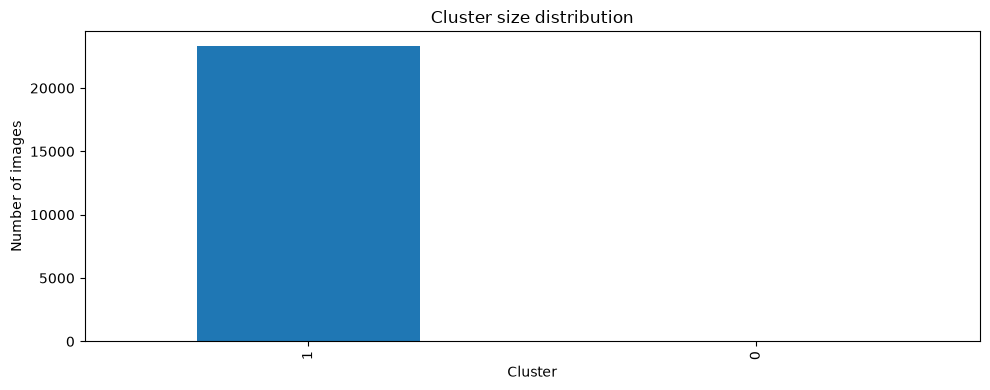

Noise ratio: 0.1702331864069387


In [27]:
sizes = joined.cluster_label.value_counts().sort_index()
plt.figure(figsize=(10,4))
sizes.drop(index=-1, errors="ignore").sort_values(ascending=False).plot(kind="bar")
plt.ylabel("Number of images"); plt.xlabel("Cluster"); plt.title("Cluster size distribution")
plt.tight_layout(); plt.show()
print("Noise ratio:", (joined.cluster_label == -1).mean())

In [28]:
# پایداری عملیاتی: هر بار 80% نمونه، همان فضای PCA 50D و پارامترهای مدل منتخب.
# برای مقایسه، ARI روی نقاط مشترک محاسبه می‌شود؛ Noise نیز یک برچسب محسوب می‌شود.
from sklearn.decomposition import PCA
Z = PCA(n_components=min(50, X.shape[1]), random_state=42).fit_transform(X)
rng = np.random.default_rng(42)
stability_rows = []
for run in range(5):
    idx = np.sort(rng.choice(len(X), size=int(.8*len(X)), replace=False))
    model = hdbscan.HDBSCAN(min_cluster_size=30, min_samples=10,
                            metric="euclidean", cluster_selection_method="eom")
    lab = model.fit_predict(Z[idx])
    # Compare with reference labels on this same subset.
    ari = adjusted_rand_score(labels[idx], lab)
    stability_rows.append({"run":run, "ari_including_noise":ari,
                           "noise_ratio":float(np.mean(lab == -1)),
                           "n_clusters":int(len(set(lab)-{-1}))})
stability = pd.DataFrame(stability_rows)
stability


,run,ari_including_noise,noise_ratio,n_clusters
0,0,-0.159391,0.735348,38
1,1,-0.157285,0.719707,37
2,2,-0.075372,0.596179,26
3,3,-0.159379,0.742368,41
4,4,-0.158430,0.746367,42


c:\Users\Lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\Lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


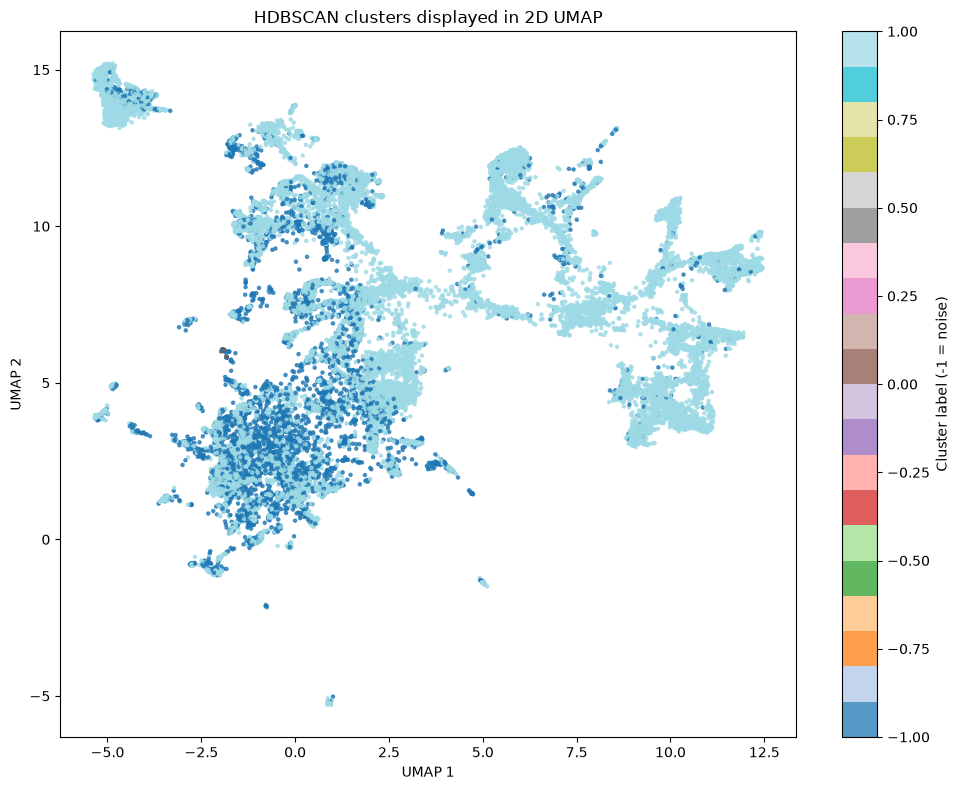

In [29]:
import umap
# UMAP را فقط برای نمایش برچسب‌های از پیش تولیدشده استفاده می‌کنیم.
reducer = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1,
                    metric="cosine", random_state=42)
coords = reducer.fit_transform(X)
plt.figure(figsize=(10,8))
scatter = plt.scatter(coords[:,0], coords[:,1], c=labels, s=5, cmap="tab20", alpha=.75)
plt.title("HDBSCAN clusters displayed in 2D UMAP")
plt.xlabel("UMAP 1"); plt.ylabel("UMAP 2")
plt.colorbar(scatter, label="Cluster label (-1 = noise)")
plt.tight_layout(); plt.show()

In [ ]:
# رتبه‌بندی بر اساس outlier score ذخیره‌شده در خروجی مدل
outlier_df = labels_df.sort_values("outlier_score", ascending=False).head(30)
outlier_df.merge(images[["image_id","image_path"]], on="image_id", how="left")

In [30]:
# رتبه‌بندی بر اساس outlier score ذخیره‌شده در خروجی مدل
outlier_df = labels_df.sort_values("outlier_score", ascending=False).head(30)
outlier_df.merge(images[["image_id","image_path"]], on="image_id", how="left")

,image_id,cluster_label,cluster_probability,outlier_score,image_path
0,bc676883-b969-43dd-b444-97750248f744,-1,0.0,0.650398,data\raw\images\birds\bc676883-b969-43dd-b444-...
1,5f8237ce-2209-47d1-a8d3-3f10a105b5a9,-1,0.0,0.639957,data\raw\images\birds\5f8237ce-2209-47d1-a8d3-...
2,6e2b54b0-8314-4971-8713-396f1d42aca8,-1,0.0,0.639441,data\raw\images\birds\6e2b54b0-8314-4971-8713-...
3,04187d26-242f-44fc-9b58-7bf7d50edfe2,-1,0.0,0.639417,data\raw\images\birds\04187d26-242f-44fc-9b58-...
4,39d38cea-0db5-485a-86aa-1ea7462b97d7,-1,0.0,0.638874,data\raw\images\birds\39d38cea-0db5-485a-86aa-...
5,915ea5ba-f9cf-47ba-97cc-03adaed0dfe1,-1,0.0,0.637519,data\raw\images\birds\915ea5ba-f9cf-47ba-97cc-...
6,e33f6b9f-a1b3-43c5-a8ae-6623c9f8e4eb,-1,0.0,0.636965,data\raw\images\birds\e33f6b9f-a1b3-43c5-a8ae-...
7,64989a09-ef1d-4e86-a561-9d9e9079ecd9,-1,0.0,0.636808,data\raw\images\birds\64989a09-ef1d-4e86-a561-...
8,7d6c314e-7d84-41b0-a791-94afdace2882,-1,0.0,0.634456,data\raw\images\birds\7d6c314e-7d84-41b0-a791-...
9,1ad18527-7d71-48ac-bab7-64097d50ad33,-1,0.0,0.634130,data\raw\images\birds\1ad18527-7d71-48ac-bab7-...


عکس ها به این خوبی اینا چرا دور افتاده باید باشن؟ به عنوان شکست hdbscan در نظر میگیرم! چاق است و گران !
در واقع ممکنه نتیجه هم بده ولی چون توی این حالتی که من اجراش کردم 5 ساعت طول میکشه نمتونم پارمتر های دیگه هم تست کنم ! 

In [31]:
tables = ROOT / "reports/tables"
tables.mkdir(parents=True, exist_ok=True)
cluster_taxonomy.to_csv(tables / "cluster_taxonomy_metrics.csv", index=False)
stability.to_csv(tables / "stability_runs.csv", index=False)
joined.to_parquet(ROOT / "reports/hdbscan_interpreted_results.parquet", index=False)
print("Interpretation outputs saved.")


Interpretation outputs saved.
